# Model checks and interpretation: v18 and v20

This notebook supports the **model interpretation** section of the report. It runs every check made so far on the two final models, then applies the methods from the course slides.

| Model | Tree branch | Network | Final combination | Public score |
|---|---|---|---|---|
| v18 | XGBoost, one model family per plant | TCN | Logistic meta-model | 0.99112 |
| v20 | AutoGluon ensemble (LightGBM, CatBoost, ExtraTrees), one predictor per plant | Same TCN | Logit blend, 20% TCN | 0.99104 |

**How to read it.** Sections 2 to 5 answer "how far can we trust the score?". Sections 6 to 10 answer "why does the model predict this?". The final section lists what can and cannot be claimed in the report.

| Slide method | Section | Applied to |
|---|---|---|
| Intrinsically interpretable (logistic model) | 6 | v18 meta-model, v20 blend |
| Permutation feature importance | 7, 10 | Tree branches, TCN |
| SHAP (TreeSHAP) | 8 | XGBoost only |
| Local surrogate (LIME-style) | 8 | XGBoost and AutoGluon |
| PDP, c-ICE | 9 | Tree branches |
| Friedman's H-statistic | 9 | Tree branches |
| Global surrogate (decision tree) | 9 | Tree branches |

**Not used:** DeepSHAP, because the TCN has about 500 input channels over 168 hours and the attributions would not be readable. Section 10 uses grouped permutation and input gradients instead.

**Important limit.** The submission pipelines do not save fitted models. Sections 7 to 10 therefore refit the models on the local training split, with one seed where the original used three. They explain models very close to the submitted ones, not the identical objects. Section 7 prints their AUC so you can compare.

**Requirements**
- In the same folder: `model_v18_meta.ipynb`, `model_v20.ipynb`, and `data/` with the raw data.
- In `data/`: `preds_v18_xgb_test.npz`, `preds_v19_ag_test.npz`, `preds_v19_tcn_test.npz`, `prediction_mapping.csv`.
- Sections 1 to 6 need no training. XGBoost takes minutes to tens of minutes. AutoGluon took about 1 hour and the TCN about 10 minutes on the original machine; set `RUN_AG` or `RUN_TCN` to `False` to skip them. Refitted models are cached on disk.


## 1. Setup

In [1]:
import json, pickle, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeRegressor, export_text

RUN_XGB, RUN_AG, RUN_TCN = True, True, True  # sections 7-10; set False to skip a refit
NB18, NB20 = 'model_v18_meta.ipynb', 'model_v20.ipynb'
BLUE, ORANGE, GREY, INK = '#2a78d6', '#eb6834', '#8d8c86', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'axes.axisbelow': True, 'font.size': 10})

def cells(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))['cells']
src = lambda c: ''.join(c['source'])

# Reuse the feature code of the models instead of copying it: run v18 up to its '# training' heading
G = {}
for c in cells(NB18):
    if c['cell_type'] == 'markdown' and src(c).strip() == '# training': break
    if c['cell_type'] == 'code': exec(src(c), G)
def cell_with(path, text):
    return next(src(c) for c in cells(path) if c['cell_type'] == 'code' and text in src(c))
exec(cell_with(NB18, 'def fit_group'), G)  # XGBoost training functions
exec(cell_with(NB18, 'class TCN'), G)      # TCN

globals().update({k: G[k] for k in ('DATA', 'T', 'units', 'plant_units', 'ORDER', 'TOPO', 'CONS', 'FEED', 'RES', 'PRICE', 'UP_PLANTS',
                                    'X_all', 'x_train', 'x_test', 'y_train', 'Y3', 'Y3te', 'auc', 'build_cases')})
lg = lambda p: np.log(np.clip(p, 1e-5, 1 - 1e-5) / (1 - np.clip(p, 1e-5, 1 - 1e-5)))
sg = lambda z: 1 / (1 + np.exp(-z))
pred = lambda s: np.load(f'{DATA}/preds_{s}.npz')['P']
Px18, Pag, Ptcn = pred('v18_xgb_test'), pred('v19_ag_test'), pred('v19_tcn_test')  # TCN: identical in v18 and v20 (same training log)
n, nu = Y3te.shape[:2]
print('cases', n, 'units', nu, 'hours', T)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/anaconda/envs/azureml_py38_PT_TF/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/anaconda/envs/azureml_py38_PT_TF/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/anaconda/envs/azureml_py38_PT_TF/lib/python3.10/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/anaconda/envs/azureml_py38_PT_TF/lib/python3.10/site-packages/traitlets/config/application.py", line 1080, 

(2337, 3243) (2337, 2352) (578, 3243) (578, 2352)
cases 578 units 14 hours 168


## 2. Performance and final combination

v18 merges the two logits with a logistic model: global weights plus small per-unit corrections. To avoid scoring it on the cases it was fitted on, every case below is predicted by a meta-model fitted on the other folds, with a 7-case gap. The v20 weight was chosen on the same local test set, so its score is slightly optimistic.

v18 XGBoost                    0.9825
v18 meta-model, out-of-fold    0.9862
v20 AutoGluon                  0.9830
v20 blend                      0.9848
TCN                            0.9723


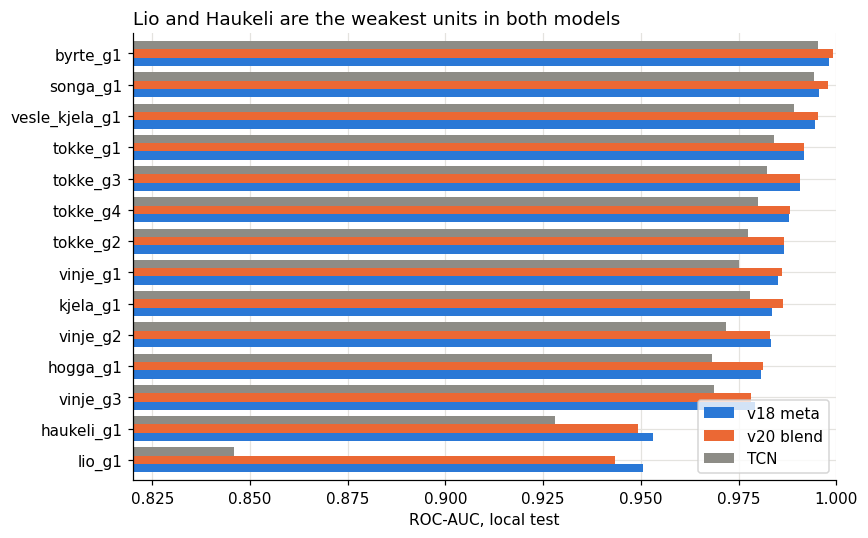

,v18 XGBoost,v18 meta,v20 AutoGluon,v20 blend,TCN
byrte_g1,0.9981,0.9981,0.9991,0.9991,0.9954
haukeli_g1,0.9227,0.9532,0.9212,0.9493,0.9279
hogga_g1,0.9802,0.9807,0.9810,0.9812,0.9683
kjela_g1,0.9799,0.9835,0.9806,0.9865,0.9780
lio_g1,0.9421,0.9506,0.9442,0.9434,0.8460
songa_g1,0.9803,0.9955,0.9919,0.9979,0.9943
tokke_g1,0.9924,0.9917,0.9923,0.9917,0.9840
tokke_g2,0.9882,0.9866,0.9866,0.9867,0.9774
tokke_g3,0.9918,0.9908,0.9915,0.9908,0.9824
tokke_g4,0.9895,0.9879,0.9881,0.9882,0.9800


In [2]:
L = np.stack([lg(Px18), lg(Ptcn)], -1)  # (cases, units, hours, models)
W20 = 0.2
def mx(L):  # global weights + per-unit intercepts and weights
    a, c = L[..., 0].ravel(), L[..., 1].ravel()
    u = np.broadcast_to(np.arange(nu)[None, :, None], L.shape[:3]).ravel()
    U = lambda v: sp.csr_matrix((v, (np.arange(len(u)), u)), shape=(len(u), nu))
    return sp.hstack([sp.csr_matrix(np.c_[a, c]), U(np.ones(len(u))), U(a), U(c)]).tocsr()
meta = lambda: LogisticRegression(C=1e-4, max_iter=500)
b = np.linspace(0, n, 6, dtype=int)
Z18 = np.zeros(Y3te.shape)
for a_, c_ in zip(b[:-1], b[1:]):
    tr, va = np.r_[0:max(a_ - 7, 0), min(c_ + 7, n):n], np.arange(a_, c_)
    Z18[va] = meta().fit(mx(L[tr]), Y3te[tr].ravel()).decision_function(mx(L[va])).reshape(len(va), nu, T)
Z20 = (1 - W20) * lg(Pag) + W20 * lg(Ptcn)
print(pd.Series({'v18 XGBoost': auc(Y3te, Px18), 'v18 meta-model, out-of-fold': auc(Y3te, Z18), 'v20 AutoGluon': auc(Y3te, Pag),
                 'v20 blend': auc(Y3te, Z20), 'TCN': auc(Y3te, Ptcn)}).round(4).to_string())
per_unit = pd.DataFrame({'v18 XGBoost': [auc(Y3te[:, u], Px18[:, u]) for u in range(nu)], 'v18 meta': [auc(Y3te[:, u], Z18[:, u]) for u in range(nu)],
                         'v20 AutoGluon': [auc(Y3te[:, u], Pag[:, u]) for u in range(nu)], 'v20 blend': [auc(Y3te[:, u], Z20[:, u]) for u in range(nu)],
                         'TCN': [auc(Y3te[:, u], Ptcn[:, u]) for u in range(nu)]}, index=units)
ax = per_unit[['v18 meta', 'v20 blend', 'TCN']].sort_values('v18 meta').plot.barh(figsize=(8, 5), color=[BLUE, ORANGE, GREY], width=.8)
ax.set_xlim(.82, 1); ax.set_xlabel('ROC-AUC, local test'); ax.set_title('Lio and Haukeli are the weakest units in both models', loc='left'); plt.tight_layout(); plt.show()
per_unit.round(4)

## 3. Stability across periods

The course slides define the split: **public = 2023, private = 2024** (to 2024-12-25). The split by period is therefore the relevant one; the random split is shown only for comparison. The gap is the absolute AUC difference between two halves of the local test set, so it indicates the size of a year-to-year change, not its direction.

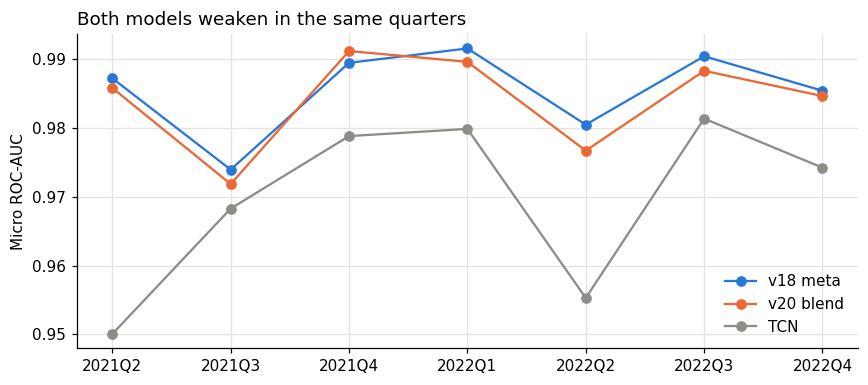

,cases,v18 meta,v18 XGBoost,v20 blend,v20 AutoGluon,TCN
2021Q2,29,0.9872,0.9880,0.9858,0.9865,0.9500
2021Q3,92,0.9739,0.9602,0.9719,0.9655,0.9683
2021Q4,92,0.9895,0.9872,0.9912,0.9889,0.9788
2022Q1,90,0.9916,0.9911,0.9896,0.9894,0.9799
2022Q2,91,0.9805,0.9730,0.9767,0.9744,0.9553
2022Q3,92,0.9904,0.9824,0.9883,0.9850,0.9814
2022Q4,92,0.9854,0.9842,0.9847,0.9836,0.9742


,v18 meta,v20 blend
"random, median",0.0009,0.0010
"random, max",0.0034,0.0047
"by period, median",0.0020,0.0014
"by period, max",0.0054,0.0059


In [3]:
qof = lambda idx: pd.DatetimeIndex(idx).tz_localize(None).to_period('Q').astype(str)
q = np.array(qof(x_test.index))
quarters = sorted(set(q))
Tq = pd.DataFrame({'cases': [(q == k).sum() for k in quarters],
                   'v18 meta': [auc(Y3te[q == k], Z18[q == k]) for k in quarters], 'v18 XGBoost': [auc(Y3te[q == k], Px18[q == k]) for k in quarters],
                   'v20 blend': [auc(Y3te[q == k], Z20[q == k]) for k in quarters], 'v20 AutoGluon': [auc(Y3te[q == k], Pag[q == k]) for k in quarters],
                   'TCN': [auc(Y3te[q == k], Ptcn[q == k]) for k in quarters]}, index=quarters)
def half_gaps(Z):
    rng = np.random.default_rng(0)
    def gap(a):
        o = np.setdiff1d(np.arange(n), a)
        return abs(auc(Y3te[a], Z[a]) - auc(Y3te[o], Z[o]))
    r = [gap(rng.choice(n, n // 2, replace=False)) for _ in range(30)]
    t = [gap((s + np.arange(n // 2)) % n) for s in range(0, n, 28)]
    return {'random, median': np.median(r), 'random, max': np.max(r), 'by period, median': np.median(t), 'by period, max': np.max(t)}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, c in (('v18 meta', BLUE), ('v20 blend', ORANGE), ('TCN', GREY)): ax.plot(Tq.index, Tq[k], marker='o', color=c, label=k)
ax.set_ylabel('Micro ROC-AUC'); ax.legend(frameon=False); ax.set_title('Both models weaken in the same quarters', loc='left'); plt.tight_layout(); plt.show()
display(Tq.round(4))
pd.DataFrame({'v18 meta': half_gaps(Z18), 'v20 blend': half_gaps(Z20)}).round(4)

## 4. Is 2023-2024 harder than the local test set?

The private labels are unavailable, so this section compares inputs only. Each model is compared with its own training data: the local test against the local training split, and the Kaggle cases against all labelled cases. A low share outside the training range means less extrapolation.

The final table matters most. Any single variable can be in range while a *combination* is new, which is why the relative price swing (weekly sd / mean price) gets its own test.

In [4]:
mp = pd.read_csv(f'{DATA}/prediction_mapping.csv'); mp['starttime'] = pd.to_datetime(mp['starttime'], utc=True)
dummy = pd.DataFrame(0, index=pd.DatetimeIndex(mp['starttime']), columns=['Run No', 'total_calculation_time', *y_train.columns])
x_kag, _ = build_cases(X_all, dummy)
def desc(x):
    P = x[PRICE].to_numpy(); rs = list(RES)
    wv = np.median(x[[f'{r}_wv_final' for r in rs]].to_numpy(), 1)
    return pd.DataFrame({'price': P.mean(1), 'weekly sd': P.std(1), 'water value': wv, 'price / wv': P.mean(1) / np.maximum(wv, 1), 'hours above wv': (P > wv[:, None]).mean(1),
                         'fill': np.mean([x[f'{r}_volume'] / RES[r]['max_vol'] for r in rs], 0), 'inflow': x.filter(like='_inflow_t').to_numpy().sum(1) / T,
                         'relative swing': P.std(1) / np.maximum(P.mean(1), 1)}, index=x.index)
Dtr, Dte, Dk = desc(x_train), desc(x_test), desc(x_kag)
tab = lambda D: D.groupby(qof(D.index)).median().assign(cases=D.groupby(qof(D.index)).size()).round(3)
display(tab(Dte).assign(auc_v18=Tq['v18 meta'].round(4)), tab(Dk))
out = lambda ref, d: ((d < ref.quantile(.01)) | (d > ref.quantile(.99))).mean().round(3)
pd.DataFrame({'local test vs train': out(Dtr, Dte), 'Kaggle vs train + test': out(pd.concat([Dtr, Dte]), Dk)})

,price,weekly sd,water value,price / wv,hours above wv,fill,inflow,relative swing,cases,auc_v18
starttime,,,,,,,,,,
2021Q2,55.666000,4.093000,47.430000,1.030,0.815,0.743,191.815002,0.073,29,0.9872
2021Q3,72.447998,9.360000,115.889999,0.602,0.000,0.725,35.855999,0.105,92,0.9739
2021Q4,113.935997,27.782000,184.735001,0.718,0.060,0.672,88.154999,0.241,92,0.9895
2022Q1,141.237000,20.450001,167.285004,0.874,0.071,0.459,21.547001,0.120,90,0.9916
2022Q2,174.578003,35.865002,231.179993,0.696,0.006,0.339,176.733994,0.189,91,0.9805
2022Q3,322.963013,82.622002,591.614990,0.535,0.000,0.617,53.730000,0.243,92,0.9904
2022Q4,134.496994,41.158001,138.854996,0.963,0.458,0.738,94.987000,0.288,92,0.9854


,price,weekly sd,water value,price / wv,hours above wv,fill,inflow,relative swing,cases
starttime,,,,,,,,,
2023Q1,105.028999,21.330999,154.014999,0.675,0.018,0.473,25.368999,0.202,90
2023Q2,85.417999,22.247999,92.209999,0.779,0.155,0.354,218.552002,0.300,91
2023Q3,61.591999,19.166000,54.244999,0.985,0.586,0.768,165.052994,0.347,92
2023Q4,69.653000,23.799999,104.025002,0.723,0.161,0.720,38.368000,0.311,92
2024Q1,59.299999,14.800000,112.209999,0.551,0.006,0.439,32.414001,0.216,91
2024Q2,44.087002,21.254999,13.430000,2.650,0.851,0.532,250.332001,0.508,91
2024Q3,38.085999,16.826000,30.440001,1.299,0.780,0.817,147.115005,0.418,92
2024Q4,46.698002,20.121000,44.230000,0.948,0.414,0.795,82.583000,0.502,86


,local test vs train,Kaggle vs train + test
price,0.941,0.000
weekly sd,0.680,0.010
water value,0.917,0.000
price / wv,0.078,0.043
hours above wv,0.000,0.000
fill,0.014,0.019
inflow,0.024,0.008
relative swing,0.066,0.132


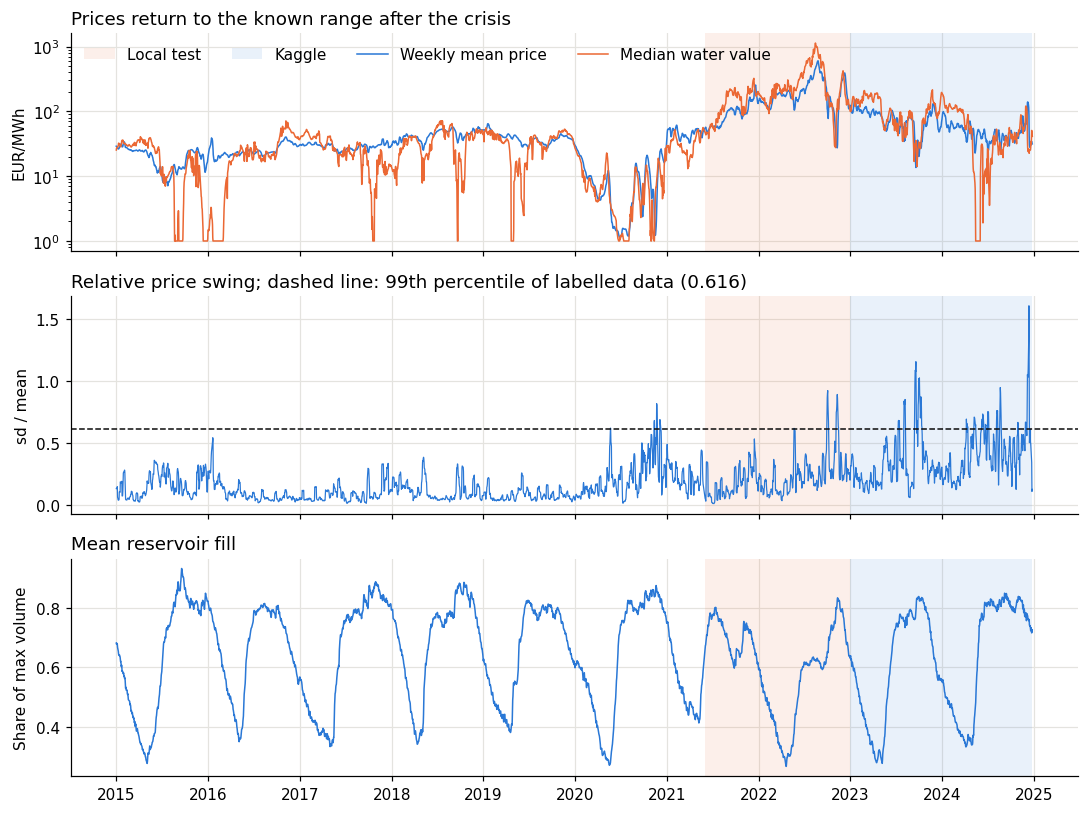

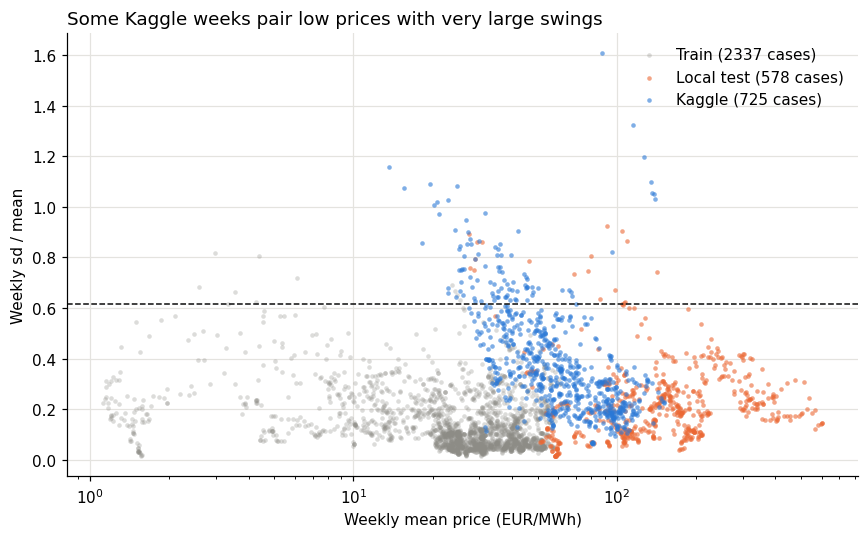

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
D_all = pd.concat([Dtr, Dte, Dk]); idx = D_all.index.tz_localize(None)
TH = pd.concat([Dtr, Dte])['relative swing'].quantile(.99)
for a in ax:
    a.axvspan(Dte.index[0].tz_localize(None), Dte.index[-1].tz_localize(None), color=ORANGE, alpha=.1, lw=0, label='Local test')
    a.axvspan(Dk.index[0].tz_localize(None), Dk.index[-1].tz_localize(None), color=BLUE, alpha=.1, lw=0, label='Kaggle')
ax[0].plot(idx, D_all['price'].clip(lower=1), color=BLUE, lw=1, label='Weekly mean price'); ax[0].plot(idx, D_all['water value'].clip(lower=1), color=ORANGE, lw=1, label='Median water value')
ax[0].set_yscale('log'); ax[0].set_ylabel('EUR/MWh'); ax[0].legend(frameon=False, ncol=4, loc='upper left'); ax[0].set_title('Prices return to the known range after the crisis', loc='left')
ax[1].plot(idx, D_all['relative swing'], color=BLUE, lw=.8); ax[1].axhline(TH, color=INK, ls='--', lw=1); ax[1].set_ylabel('sd / mean'); ax[1].set_title(f'Relative price swing; dashed line: 99th percentile of labelled data ({TH:.3f})', loc='left')
ax[2].plot(idx, D_all['fill'], color=BLUE, lw=1); ax[2].set_ylabel('Share of max volume'); ax[2].set_title('Mean reservoir fill', loc='left'); plt.tight_layout(); plt.show()

fig, a = plt.subplots(figsize=(8, 5))
for D, c, l, al in ((Dtr, GREY, 'Train', .3), (Dte, ORANGE, 'Local test', .6), (Dk, BLUE, 'Kaggle', .6)):
    a.scatter(D['price'].clip(lower=1), D['relative swing'], s=9, color=c, alpha=al, lw=0, label=f'{l} ({len(D)} cases)')
a.set_xscale('log'); a.axhline(TH, color=INK, ls='--', lw=1); a.set_xlabel('Weekly mean price (EUR/MWh)'); a.set_ylabel('Weekly sd / mean'); a.legend(frameon=False)
a.set_title('Some Kaggle weeks pair low prices with very large swings', loc='left'); plt.tight_layout(); plt.show()

## 5. Volatile weeks and the 50/50 split

This section checks how the models do on local weeks with a large relative swing, and how many such weeks each half of the Kaggle cases could contain. The top row has few cases from few separate episodes, so treat it as an indication only.

In [6]:
r = Dte['relative swing'].to_numpy()
bands = {'below 0.3': r < .3, f'0.3 to {TH:.3f}': (r >= .3) & (r <= TH), f'above {TH:.3f}': r > TH}
display(pd.DataFrame({k: {'cases': m.sum(), 'v18 meta': auc(Y3te[m], Z18[m]), 'v20 blend': auc(Y3te[m], Z20[m]), 'TCN': auc(Y3te[m], Ptcn[m])} for k, m in bands.items() if m.sum()}).T.round(4))
print('Local start dates above threshold:', list(x_test.index[r > TH].strftime('%Y-%m-%d')))
h = (Dk['relative swing'] > TH).to_numpy(); m_ = len(h) // 2
wins = [h[s:s + m_].mean() for s in range(len(h) - m_ + 1)]
rng = np.random.default_rng(0); rand = [h[rng.choice(len(h), m_, replace=False)].mean() for _ in range(5000)]
print(f'Kaggle share above threshold: {h.mean():.3f} (train {(Dtr["relative swing"] > TH).mean():.3f}, local test {(r > TH).mean():.3f})')
print(f'Share in a contiguous half: {min(wins):.3f} to {max(wins):.3f}; in a random half, 1st-99th percentile: {np.percentile(rand, 1):.3f} to {np.percentile(rand, 99):.3f}')
display(pd.Series(h, index=Dk.index).groupby(qof(Dk.index)).mean().round(3).to_frame('share above threshold').T)

,cases,v18 meta,v20 blend,TCN
below 0.3,447.0,0.9854,0.9838,0.9711
0.3 to 0.616,112.0,0.9937,0.9933,0.9827
above 0.616,19.0,0.9455,0.9411,0.9313


Local start dates above threshold: ['2022-05-22', '2022-05-23', '2022-09-30', '2022-10-01', '2022-10-02', '2022-10-03', '2022-10-04', '2022-10-05', '2022-10-06', '2022-11-06', '2022-11-07', '2022-11-08', '2022-11-09', '2022-11-10', '2022-11-11', '2022-11-12', '2022-11-13', '2022-11-14', '2022-11-15']
Kaggle share above threshold: 0.132 (train 0.005, local test 0.033)
Share in a contiguous half: 0.105 to 0.191; in a random half, 1st-99th percentile: 0.102 to 0.163


starttime,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
share above threshold,0.0,0.0,0.272,0.141,0.0,0.286,0.185,0.174


## 6. Intrinsically interpretable layer: how the branches are combined

The final layer of both models is a linear combination of logits, so it can be read directly. A larger coefficient means that branch moves the final score more. Because the meta-model uses strong regularization (C = 1e-4) and its inputs are not standardized, read the coefficients as relative trust between branches, not as causal effects.

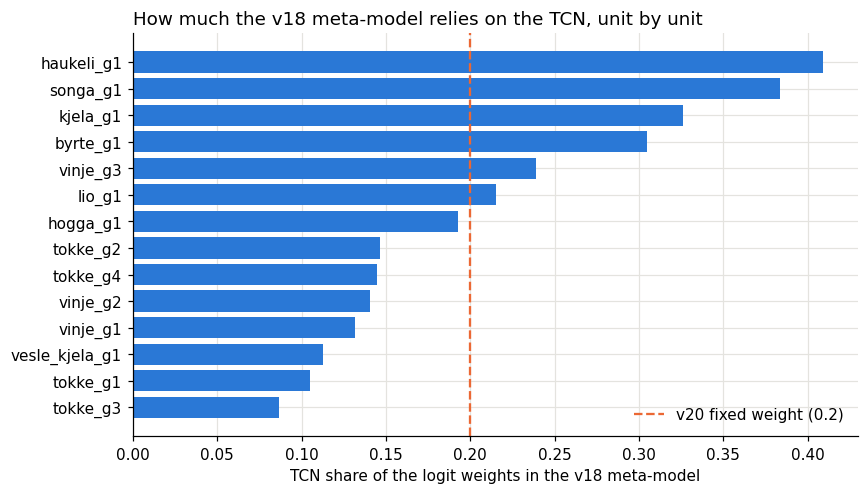

Global weights: XGBoost 0.696, TCN 0.191; global intercept -0.163


,XGBoost weight,TCN weight,TCN share
tokke_g3,0.800,0.076,0.087
tokke_g1,0.801,0.094,0.105
vesle_kjela_g1,0.772,0.098,0.112
vinje_g1,0.810,0.123,0.131
vinje_g2,0.817,0.133,0.140
tokke_g4,0.738,0.125,0.145
tokke_g2,0.713,0.122,0.146
hogga_g1,0.766,0.183,0.193
lio_g1,0.847,0.233,0.216
vinje_g3,0.795,0.249,0.239


In [7]:
M = meta().fit(mx(L), Y3te.ravel()); w = M.coef_[0]
wX = w[0] + w[2 + nu:2 + 2 * nu]; wT = w[1] + w[2 + 2 * nu:2 + 3 * nu]
W = pd.DataFrame({'XGBoost weight': wX, 'TCN weight': wT, 'TCN share': wT / (wX + wT)}, index=units).sort_values('TCN share')
fig, a = plt.subplots(figsize=(8, 4.6)); a.barh(W.index, W['TCN share'], color=BLUE); a.axvline(W20, color=ORANGE, ls='--', label=f'v20 fixed weight ({W20})')
a.set_xlabel('TCN share of the logit weights in the v18 meta-model'); a.legend(frameon=False); a.set_title('How much the v18 meta-model relies on the TCN, unit by unit', loc='left'); plt.tight_layout(); plt.show()
print(f'Global weights: XGBoost {w[0]:.3f}, TCN {w[1]:.3f}; global intercept {M.intercept_[0]:.3f}')
W.round(3)

## 7. Refit the tree branches and measure grouped permutation importance

**Method (slides: permutation feature importance).** Shuffle a feature and measure how much the score drops. Here the score is ROC-AUC and whole feature **groups** are shuffled, because features inside a group are strongly correlated and would otherwise substitute for each other. Values are shuffled between cases at the same hour, so the daily and weekly structure is preserved.

Importance is measured on the local test set, for one plant model at a time. A shuffled upstream group shows how much the plant depends on the cascade.

In [8]:
def feature_names(plant, stacked=True):
    up, dn = TOPO[plant]; rs = up + ([dn] if dn else [])
    N = ['hour_of_week', 'hour_of_day', 'day_of_week', 'log_price_rel', 'log_price_rel_prev', 'log_price_rel_next', 'price_rank_week', 'price_rank_day',
         'price_z_day', 'price_z_week', 'log_price_wv_source', 'inflow', 'inflow_week_mean']
    if stacked: N += ['up_prob', 'up_prob_lag1', 'up_prob_lag3', 'up_prob_week_mean']
    N += [f'cons_{k}' for k in CONS.get(plant, [])] + ['vol_above_min', 'downstream_shortfall']
    if plant == 'lio': N += ['need_release', 'need_release_cum', 'need_release_week']
    N += [f'log_price_wv_{r}_{w}' for r in rs for w in ('init', 'final')] + ['inflow_cum', 'spill_pressure']
    N += [f'{k}_{b}' for k in ('dispatch', 'budget') for b in ('min', 'wv_init', 'wv_final', 'max')]
    if stacked: N += ['up_release', 'up_release_cum']
    N += [f'{r}_{s}' for r in rs for s in ('volume', 'logwv_init', 'logwv_final')] + [f'{r}_fill' for r in rs] + ['head', 'net_head', 'dlogwv_source_down', 'day_of_year', 'feeder_water']
    return N
UNIT = ['vit_water', 'vit_power', 'vit_budget', 'vit_water_pos', 'vit_budget_pos', 'power_ratio', 'log_threshold_wv', 'lp_flow', 'lp_reduced_cost']
IDENT = ['unit_id', 'unit_pos', 'profile_minus_pos']
def group_of(f):
    rules = [('Upstream commitment', ('up_prob',)), ('Upstream release', ('up_release',)), ('Cascade LP', ('lp_',)), ('Unit physics', ('vit_', 'power_ratio', 'log_threshold')),
             ('Surrogate', ('dispatch_', 'budget_', 'profile')), ('Unit identity', ('unit_',)), ('Constraints', ('cons_', 'vol_above', 'downstream_short', 'need_release')),
             ('Spill pressure', ('inflow_cum', 'spill_')), ('Inflow', ('inflow',)), ('Price vs water value', ('log_price_wv',)), ('Price shape', ('log_price_rel', 'price_')),
             ('Calendar', ('hour_', 'day_of_week')), ('Season and feeder', ('day_of_year', 'feeder'))]
    return next((g for g, ps in rules if f.startswith(ps)), 'Reservoir state')
tree_names = lambda p: feature_names(p) + UNIT + IDENT if UP_PLANTS.get(p) else feature_names(p, False) + UNIT + IDENT

def capture(ns, make_key):
    # wrap fit_group so the refit keeps its test design matrix (and, through make_key, its model)
    orig, store, plants = ns['fit_group'], {}, iter(ORDER)
    def wrapped(B, Bt, us, var, cw=None):
        p = next(plants); make_key(p); o = orig(B, Bt, us, var, cw)
        nt = len(Bt) // T; X = ns['design'](Bt, np.arange(nt), us, var)
        assert X.shape[1] == len(tree_names(p)), (p, X.shape[1], len(tree_names(p)))
        store[p] = {'X': X, 'Y': Y3te[:, us, :].transpose(1, 0, 2).ravel(), 'nu': len(us), 'names': tree_names(p)}
        return o
    ns['fit_group'] = wrapped
    return store

VAR = {p: 'L' for p in ORDER}
f18 = Path(DATA) / 'interp_v18.pkl'
if f18.exists(): R18 = pickle.loads(f18.read_bytes())
elif RUN_XGB:
    G['SEEDS'] = 1; models, cur, mk0 = {}, [None], G['mk']
    def mk_rec(seed):
        m = mk0(seed); models.setdefault(cur[0], m)  # first model of a plant = refit on all training cases
        return m
    G['mk'] = mk_rec
    fg0 = G['fit_group']; store = capture(G, lambda p: cur.__setitem__(0, p))
    P_refit = G['run'](VAR, x_train, x_test)[0]; G['fit_group'] = fg0; G['mk'] = mk0
    print(f'Refit XGBoost, one seed: {auc(Y3te, P_refit):.4f} (submitted pipeline: {auc(Y3te, Px18):.4f})')
    R18 = {p: {**store[p], 'model': models[p]} for p in ORDER}; f18.write_bytes(pickle.dumps(R18))
else: R18 = None

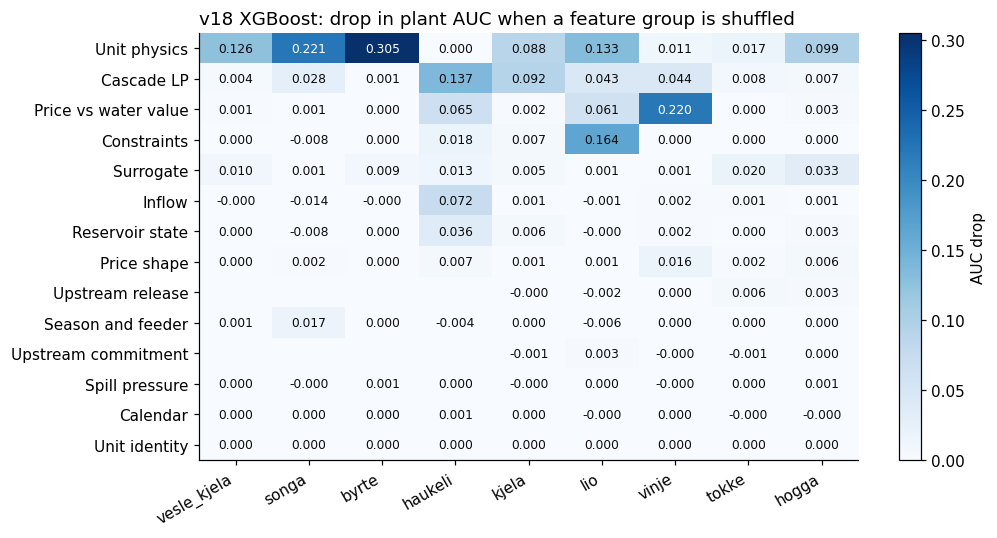

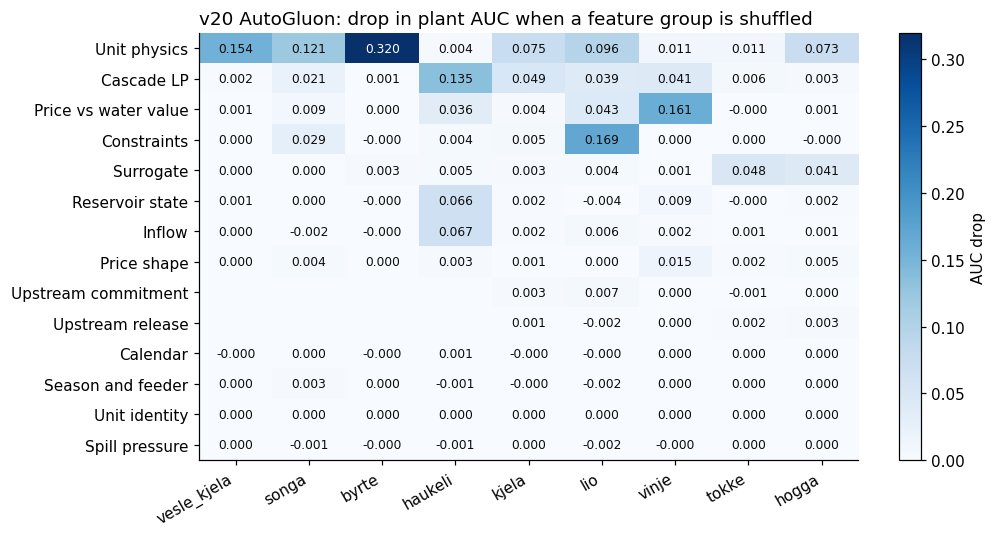

In [9]:
class KeepDir:  # replaces TemporaryDirectory so the AutoGluon predictors stay on disk
    def __init__(self, path): self.path = path
    def __enter__(self):
        shutil.rmtree(self.path, ignore_errors=True); Path(self.path).mkdir(parents=True); return self.path
    def __exit__(self, *a): return False

f20 = Path(DATA) / 'interp_v20.pkl'; AG_DIR = Path(DATA) / 'interp_ag'
if RUN_AG or f20.exists():
    from autogluon.tabular import TabularPredictor
    from autogluon.features.generators import IdentityFeatureGenerator
if f20.exists(): R20 = pickle.loads(f20.read_bytes())
elif RUN_AG:
    H = dict(G); H.update(TabularPredictor=TabularPredictor, IdentityFeatureGenerator=IdentityFeatureGenerator)
    exec(cell_with(NB20, 'def fit_group'), H)
    cur = [None]; H['TemporaryDirectory'] = lambda: KeepDir(str(AG_DIR / cur[0]))
    store = capture(H, lambda p: cur.__setitem__(0, p))
    P_refit = H['run'](VAR, x_train, x_test)[0]
    print(f'Refit AutoGluon: {auc(Y3te, P_refit):.4f} (submitted pipeline: {auc(Y3te, Pag):.4f})')
    R20 = store; f20.write_bytes(pickle.dumps(R20))
else: R20 = None

def xgb_fn(p):
    m = R18[p]['model']
    return lambda X: lg(m.predict_proba(X)[:, 1])
def ag_fn(p):
    m = TabularPredictor.load(str(AG_DIR / p / 'm'), verbosity=0); cols = [f'f{i}' for i in range(R20[p]['X'].shape[1])]
    return lambda X: lg(m.predict_proba(pd.DataFrame(X, columns=cols), as_multiclass=False).to_numpy())
SETS = {k: (R, fn) for k, R, fn in (('v18 XGBoost', R18, xgb_fn), ('v20 AutoGluon', R20, ag_fn)) if R is not None}

def perm_groups(fn, R, step=3, seed=0):
    X0, Y0, nun = R['X'], R['Y'], R['nu']; idx = np.arange(len(Y0)).reshape(nun, -1, T)
    pick = idx[:, ::step].ravel(); X, Y = X0[pick].copy(), Y0[pick]; nc = idx[:, ::step].shape[1]; pos = np.arange(len(Y)).reshape(nun, nc, T)
    base_auc = roc_auc_score(Y, fn(X)); g = np.array([group_of(f) for f in R['names']]); rng = np.random.default_rng(seed); res = {}
    for k in pd.unique(g):
        cols = np.where(g == k)[0]; rows = pos[:, rng.permutation(nc)].ravel(); keep = X[:, cols].copy()
        X[:, cols] = X[rows][:, cols]; res[k] = base_auc - roc_auc_score(Y, fn(X)); X[:, cols] = keep
    return res
IMP = {k: pd.DataFrame({p: perm_groups(fn(p), R[p]) for p in ORDER}) for k, (R, fn) in SETS.items()}
for k, D in IMP.items():
    O = D.mean(axis=1).sort_values(ascending=False).index; D = D.loc[O]
    fig, a = plt.subplots(figsize=(9.5, 5)); im = a.imshow(D.fillna(0), cmap='Blues', aspect='auto', vmin=0)
    a.set_xticks(range(len(D.columns)), D.columns, rotation=30, ha='right'); a.set_yticks(range(len(D)), D.index); a.grid(False)
    for i in range(len(D)):
        for j in range(len(D.columns)):
            v = D.iloc[i, j]
            if pd.notna(v): a.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8, color='white' if v > .6 * np.nanmax(D.values) else INK)
    a.set_title(f'{k}: drop in plant AUC when a feature group is shuffled', loc='left'); plt.colorbar(im, label='AUC drop'); plt.tight_layout(); plt.show()

## 8. Local explanations: why is a unit on at a given hour?

**TreeSHAP (XGBoost).** Each prediction splits exactly into one contribution per feature, in log-odds. This uses XGBoost's exact built-in computation, and contributions are summed by group. The first chart gives the global view; the second follows the hardest week for one plant, hour by hour.

**Local surrogate (both tree branches).** The ensemble in v20 has no single exact SHAP computation here, so the same question is answered in a model-agnostic way, in the spirit of LIME. For one hour, random feature groups are replaced with values from other cases, and a linear model is fitted to the change in prediction. Its coefficients are the local effect of each group. As the slides warn, the result depends on this choice of perturbation, and correlated features make any single attribution less stable.

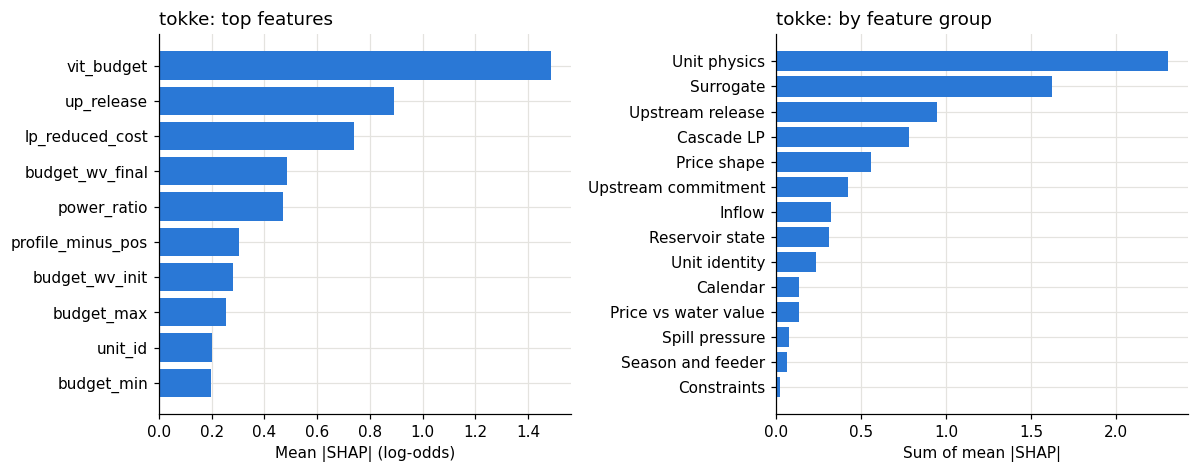

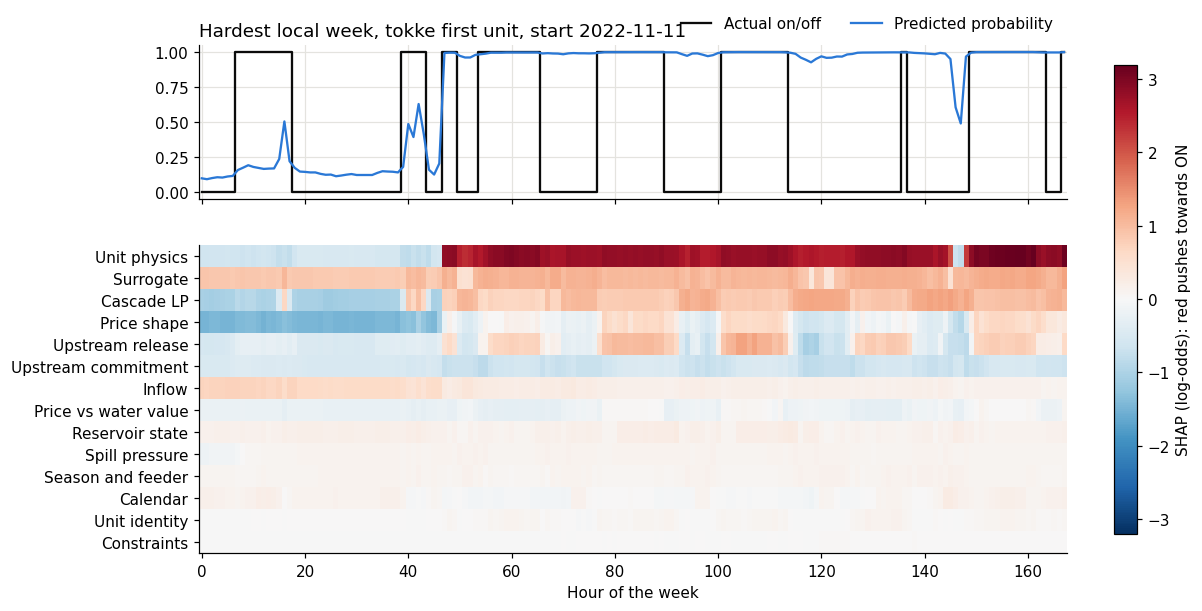

In [10]:
PLANT, TOP = 'tokke', 10  # change PLANT to explore another model (e.g. 'lio', 'haukeli')
if 'v18 XGBoost' in SETS:
    import xgboost as xgb
    def shap_vals(p, step=14):
        R = R18[p]; idx = np.arange(len(R['Y'])).reshape(R['nu'], -1, T)[:, ::step].ravel()
        return R['model'].get_booster().predict(xgb.DMatrix(R['X'][idx]), pred_contribs=True)[:, :-1], idx
    S, _ = shap_vals(PLANT); mean_abs = pd.Series(np.abs(S).mean(0), index=R18[PLANT]['names']).sort_values(ascending=False)
    groups = mean_abs.groupby([group_of(f) for f in mean_abs.index]).sum().sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    ax[0].barh(mean_abs.index[:TOP][::-1], mean_abs.values[:TOP][::-1], color=BLUE); ax[0].set_xlabel('Mean |SHAP| (log-odds)'); ax[0].set_title(f'{PLANT}: top features', loc='left')
    ax[1].barh(groups.index, groups.values, color=BLUE); ax[1].set_xlabel('Sum of mean |SHAP|'); ax[1].set_title(f'{PLANT}: by feature group', loc='left'); plt.tight_layout(); plt.show()

    # hardest week for the plant's first unit: highest log-loss among local test cases
    R = R18[PLANT]; nc = len(R['Y']) // (R['nu'] * T); Yp = R['Y'].reshape(R['nu'], nc, T)[0]; Zp = xgb_fn(PLANT)(R['X'][:nc * T]).reshape(nc, T)
    loss = -(Yp * np.log(sg(Zp) + 1e-9) + (1 - Yp) * np.log(1 - sg(Zp) + 1e-9)).mean(1); case = int(np.argmax(loss))
    Sc = R['model'].get_booster().predict(xgb.DMatrix(R['X'][case * T:(case + 1) * T]), pred_contribs=True)[:, :-1]
    GS = pd.DataFrame(Sc, columns=R['names']).T.groupby([group_of(f) for f in R['names']]).sum(); GS = GS.loc[GS.abs().sum(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[1, 2]))
    ax[0].step(range(T), Yp[case], color=INK, where='mid', label='Actual on/off'); ax[0].plot(sg(Zp[case]), color=BLUE, label='Predicted probability'); ax[0].legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1)); ax[0].set_title(f'Hardest local week, {PLANT} first unit, start {x_test.index[case].date()}', loc='left')
    lim = np.abs(GS.values).max(); im = ax[1].imshow(GS.values, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim, interpolation='nearest'); ax[1].set_yticks(range(len(GS)), GS.index); ax[1].grid(False); ax[1].set_xlabel('Hour of the week')
    fig.colorbar(im, ax=ax, label='SHAP (log-odds): red pushes towards ON', fraction=.025); plt.show()

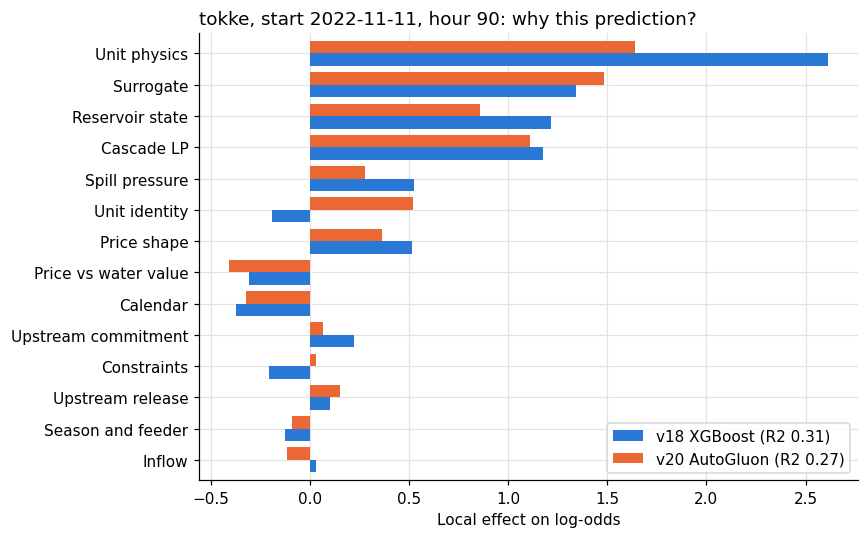

In [11]:
def local_surrogate(fn, R, row, draws=256, seed=0):
    # group-level LIME: replace random groups with values from other rows, fit weights on the change in prediction
    rng = np.random.default_rng(seed); g = np.array([group_of(f) for f in R['names']]); ks = list(pd.unique(g)); X = R['X']
    x = X[row]; D = np.repeat(x[None], draws, 0); A = rng.integers(0, 2, (draws, len(ks))); bg = X[rng.integers(0, len(X), draws)]
    for i, k in enumerate(ks):
        cols = np.where(g == k)[0]; rows = np.where(A[:, i])[0]; D[np.ix_(rows, cols)] = bg[np.ix_(rows, cols)]
    y = fn(D); m = LinearRegression().fit(1 - A, y); return pd.Series(m.coef_, index=ks), m.score(1 - A, y)
if SETS:
    ref = next(iter(SETS.values()))[0][PLANT]; nc = len(ref['Y']) // (ref['nu'] * T)
    case_, hour_ = (case, int(np.argmax(np.abs(Yp[case] - sg(Zp[case]))))) if 'case' in globals() else (nc // 2, 100)
    row = case_ * T + hour_; out_ = {}
    for k, (R, fn) in SETS.items():
        coef, r2 = local_surrogate(fn(PLANT), R[PLANT], row); out_[f'{k} (R2 {r2:.2f})'] = coef
    Lc = pd.DataFrame(out_); Lc = Lc.loc[Lc.abs().max(axis=1).sort_values().index]
    ax = Lc.plot.barh(figsize=(8, 5), color=[BLUE, ORANGE][:Lc.shape[1]], width=.8); ax.set_xlabel('Local effect on log-odds'); ax.set_title(f'{PLANT}, start {x_test.index[case_].date()}, hour {hour_}: why this prediction?', loc='left'); plt.tight_layout(); plt.show()

### Why the hardest Tokke week fails

The next chart counts units instead of following one unit. If actual and expected counts matched, the error would only concern *which* of the four identical units runs. The second check tests a mechanism found in that week: when the water value of Vinjevatn is close to zero, the price exceeds it in almost every hour, so the economic features stop separating hours.

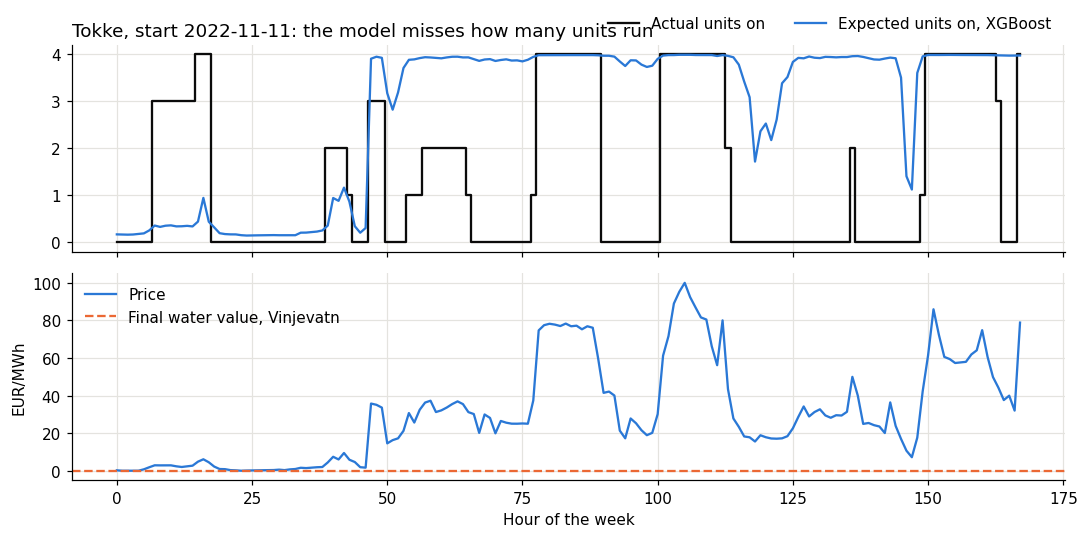

,v18 meta,v20 blend
water value < 5,0.9284,0.9499
other cases,0.9913,0.9918


Share of cases with low water value: train 0.212, local test 0.083, Kaggle 0.112


,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
Kaggle share,0.111,0.198,0.065,0.109,0.044,0.099,0.141,0.128


In [12]:
if 'case' in globals():
    us = plant_units['tokke']; pr = x_test.iloc[case][PRICE].to_numpy(dtype=float)
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    ax[0].step(range(T), Y3te[case, us].sum(0), where='mid', color=INK, label='Actual units on'); ax[0].plot(sg(lg(Px18[case, us])).sum(0), color=BLUE, label='Expected units on, XGBoost')
    ax[0].legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1)); ax[0].set_title(f'Tokke, start {x_test.index[case].date()}: the model misses how many units run', loc='left')
    ax[1].plot(pr, color=BLUE, label='Price'); ax[1].axhline(x_test.iloc[case]['vinjevatn_wv_final'], color=ORANGE, ls='--', label='Final water value, Vinjevatn'); ax[1].set_ylabel('EUR/MWh'); ax[1].set_xlabel('Hour of the week'); ax[1].legend(frameon=False); plt.tight_layout(); plt.show()
LOW = 5  # EUR/MWh
wv_v = lambda x: x['vinjevatn_wv_final'].to_numpy(); us = plant_units['tokke']; m_low = wv_v(x_test) < LOW
if m_low.sum():
    display(pd.DataFrame({k: {'water value < 5': auc(Y3te[m_low][:, us], Z[m_low][:, us]), 'other cases': auc(Y3te[~m_low][:, us], Z[~m_low][:, us])} for k, Z in (('v18 meta', Z18), ('v20 blend', Z20))}).round(4))
print(f'Share of cases with low water value: train {(wv_v(x_train) < LOW).mean():.3f}, local test {m_low.mean():.3f}, Kaggle {(wv_v(x_kag) < LOW).mean():.3f}')
display(pd.Series(wv_v(x_kag) < LOW).groupby(np.array(qof(x_kag.index))).mean().round(3).to_frame('Kaggle share').T)

## 9. Global effects: PDP, c-ICE, H-statistic and surrogate trees

**PDP and c-ICE.** The thick line is the average effect on the log-odds when one feature is forced to a value; thin lines are individual hours, all anchored at the lowest value. A strong spread among thin lines means the average hides different behaviours. Forcing one feature ignores its correlation with others, so values outside the data's normal combinations are unreliable: this is the independence assumption mentioned in the slides.

**H-statistic.** It measures how much of the joint effect of two features is not additive: 0 means no interaction, and larger values mean a stronger one. Only a small sample is used because the cost grows quadratically. The pairs below were selected from the surrogate trees, so they are candidates for interaction, not a random sample of pairs.

**Global surrogate.** A depth-3 decision tree is fitted to the model's own log-odds, not to the labels. If R² is high, the printed rules are a fair simplified description of that plant model. If it is low, the rules should not be used to describe the model.


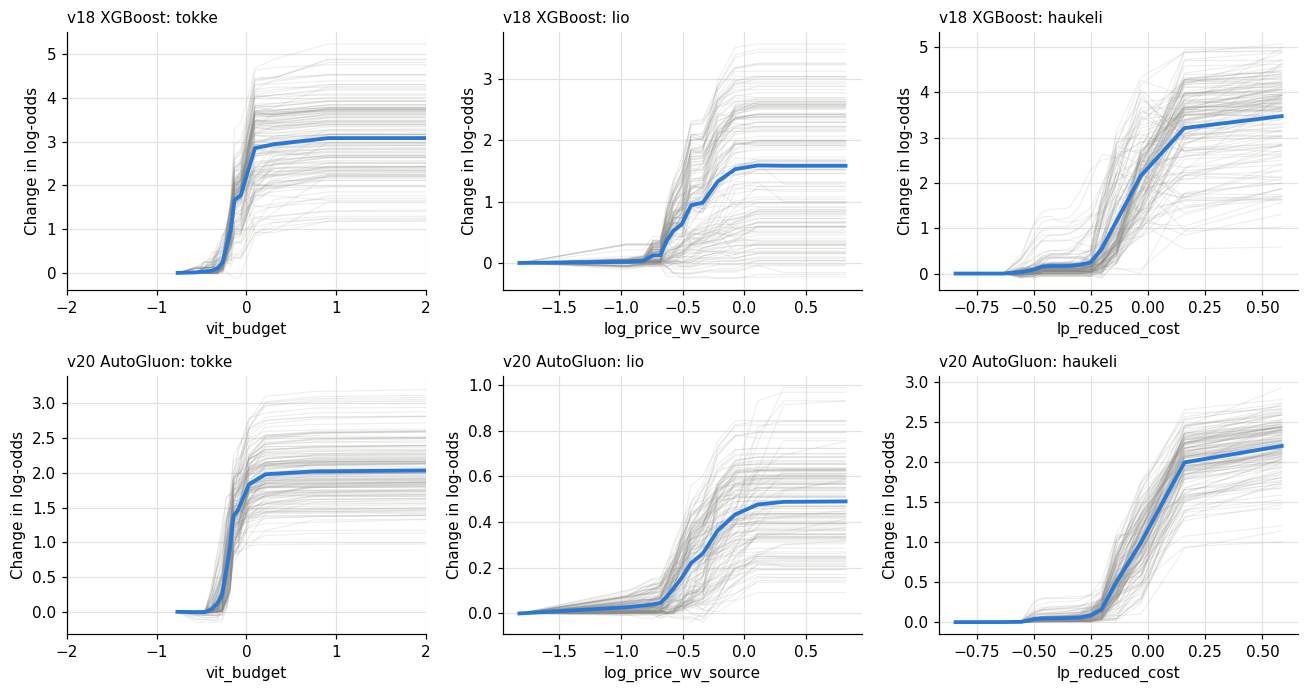

In [13]:
TARGETS = [('tokke', 'vit_budget'), ('lio', 'log_price_wv_source'), ('haukeli', 'lp_reduced_cost')]  # (plant, feature): edit freely
def ice(fn, R, f, grid_n=15, rows_n=150, seed=0):
    j = R['names'].index(f); X = R['X']; rng = np.random.default_rng(seed); s = X[rng.choice(len(X), min(rows_n, len(X)), replace=False)]
    grid = np.unique(np.quantile(X[:, j], np.linspace(.02, .98, grid_n))); Z = np.empty((len(s), len(grid)))
    for i, v in enumerate(grid):
        t = s.copy(); t[:, j] = v; Z[:, i] = fn(t)
    return grid, Z - Z[:, [0]]
if SETS:
    fig, ax = plt.subplots(len(SETS), len(TARGETS), figsize=(4 * len(TARGETS), 3.2 * len(SETS)), squeeze=False)
    for r, (k, (R, fn)) in enumerate(SETS.items()):
        for c, (p, f) in enumerate(TARGETS):
            grid, Z = ice(fn(p), R[p], f); a = ax[r, c]; a.plot(grid, Z.T, color=GREY, alpha=.15, lw=.7); a.plot(grid, Z.mean(0), color=BLUE, lw=2.5)
            a.set_title(f'{k}: {p}', loc='left', fontsize=10); a.set_xlabel(f); a.set_ylabel('Change in log-odds')
            if f == 'vit_budget': a.set_xlim(-2, 2)
    plt.tight_layout(); plt.show()

In [14]:
PAIRS = [('tokke', 'vit_budget', 'up_prob'), ('tokke', 'vit_budget', 'budget_wv_final'), ('lio', 'vit_power', 'need_release'), ('lio', 'lp_flow', 'need_release'),
         ('haukeli', 'lp_reduced_cost', 'vinjevatn_logwv_final'), ('haukeli', 'lp_flow', 'log_price_wv_vinjevatn_final')]  # pairs suggested by the surrogate trees
def h_stat(fn, R, a_, b_, m=40, seed=0):
    X = R['X']; s = X[np.random.default_rng(seed).choice(len(X), m, replace=False)]; ja, jb = R['names'].index(a_), R['names'].index(b_)
    def pd_at(cols):
        o = np.empty(m)
        for i in range(m):
            t = s.copy(); t[:, cols] = s[i, cols]; o[i] = fn(t).mean()
        return o - o.mean()
    A, B, AB = pd_at([ja]), pd_at([jb]), pd_at([ja, jb])
    return ((AB - A - B)**2).sum() / max((AB**2).sum(), 1e-12)
if SETS:
    display(pd.DataFrame({k: {f'{p}: {a_} x {b_}': h_stat(fn(p), R[p], a_, b_) for p, a_, b_ in PAIRS} for k, (R, fn) in SETS.items()}).round(3).rename_axis('H squared'))
    for k, (R, fn) in SETS.items():
        for p in ('tokke', 'lio', 'haukeli'):
            X = R[p]['X'][::7]; y = fn(p)(X); t = DecisionTreeRegressor(max_depth=3, min_samples_leaf=200, random_state=0).fit(X, y)
            print(f'--- {k}, {p}: surrogate R2 = {t.score(X, y):.3f}'); print(export_text(t, feature_names=R[p]['names'], decimals=2))

,v18 XGBoost,v20 AutoGluon
H squared,,
tokke: vit_budget x up_prob,0.002,0.005
tokke: vit_budget x budget_wv_final,0.007,0.018
lio: vit_power x need_release,0.001,0.000
lio: lp_flow x need_release,0.003,0.007
haukeli: lp_reduced_cost x vinjevatn_logwv_final,0.014,0.002
haukeli: lp_flow x log_price_wv_vinjevatn_final,0.003,0.002


--- v18 XGBoost, tokke: surrogate R2 = 0.928
|--- vit_budget <= -0.12
|   |--- vit_budget <= -0.23
|   |   |--- budget_min <= 0.13
|   |   |   |--- value: [-7.03]
|   |   |--- budget_min >  0.13
|   |   |   |--- value: [-4.36]
|   |--- vit_budget >  -0.23
|   |   |--- budget_wv_final <= 0.19
|   |   |   |--- value: [-4.10]
|   |   |--- budget_wv_final >  0.19
|   |   |   |--- value: [-0.75]
|--- vit_budget >  -0.12
|   |--- up_prob <= 0.39
|   |   |--- vit_budget <= -0.02
|   |   |   |--- value: [0.78]
|   |   |--- vit_budget >  -0.02
|   |   |   |--- value: [3.75]
|   |--- up_prob >  0.39
|   |   |--- vit_budget <= 0.34
|   |   |   |--- value: [4.90]
|   |   |--- vit_budget >  0.34
|   |   |   |--- value: [6.96]

--- v18 XGBoost, lio: surrogate R2 = 0.887
|--- vit_power <= -0.09
|   |--- need_release <= 2.36
|   |   |--- vit_water <= -0.19
|   |   |   |--- value: [-4.84]
|   |   |--- vit_water >  -0.19
|   |   |   |--- value: [-0.46]
|   |--- need_release >  2.36
|   |   |--- lp_reduc

## 10. Inside the TCN

The TCN takes all plants at once, so it can answer a question the plant models cannot: **does it use information from other plants?** A single-seed network is refitted with the original settings.

- **Group importance:** shuffle a feature group across all plants and measure the AUC drop.
- **Plant-to-plant matrix:** shuffle all channels of one plant (column) and measure the AUC drop of each target plant (row). Values away from the diagonal show the network using other plants' inputs.
- **Time profile:** the average input gradient by distance between input hour and output hour. It shows how far in time the network looks in practice. Gradients measure local sensitivity, not contribution.

Refit TCN, one seed: 0.9706 (three seeds: 0.9723)


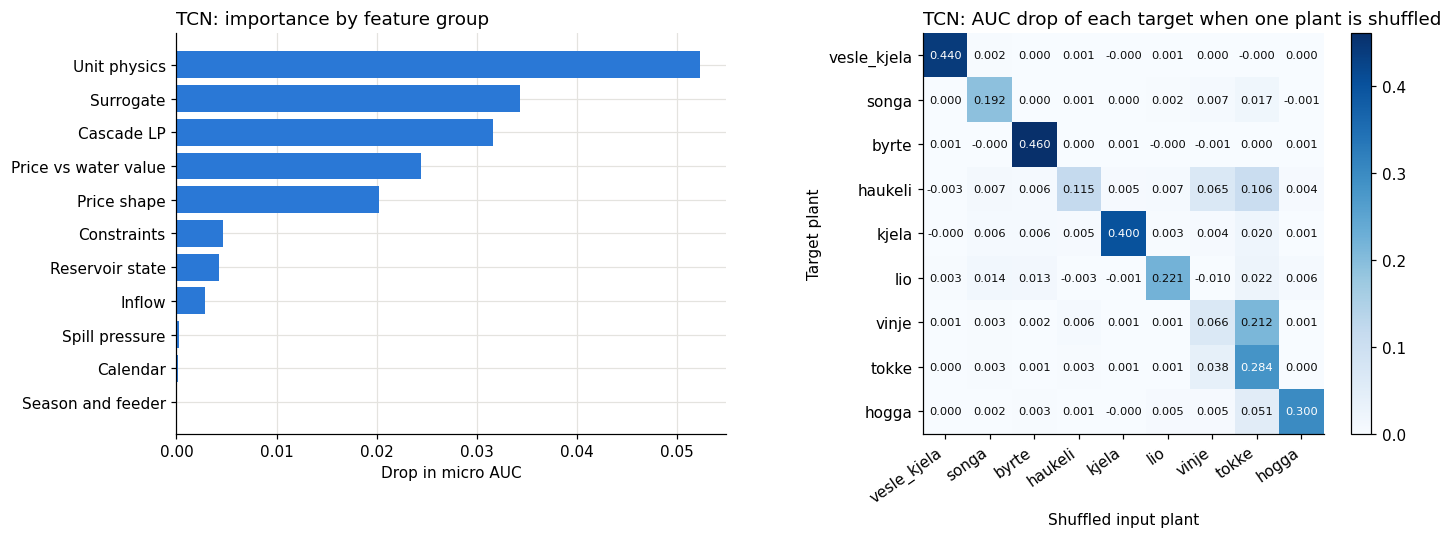

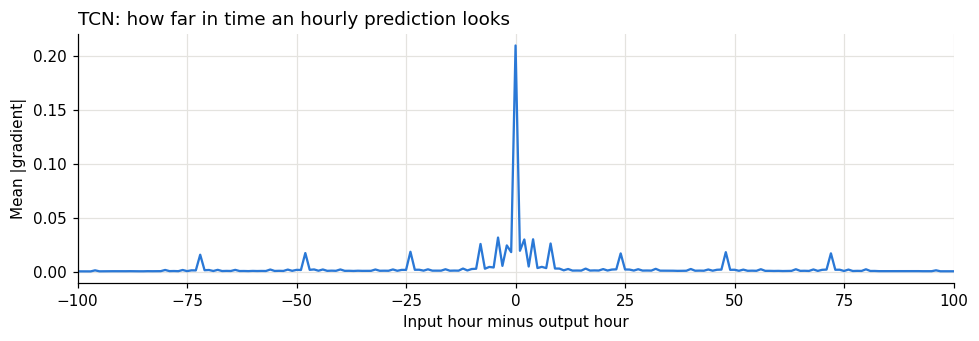

In [15]:
if RUN_TCN or (Path(DATA) / 'interp_tcn.pt').exists():
    import torch, torch.nn as nn
    DEV = G['DEV']; tensor, scaled = G['tensor'], G['scaled']
    A = tensor(x_train); sd_ = A.std((0, 2), dtype=np.float64); keep = sd_ > 1e-4
    mu = A.mean((0, 2), dtype=np.float64)[keep][None, :, None].astype(np.float32); sd_ = sd_[keep][None, :, None].astype(np.float32)
    tt = lambda a: torch.tensor(np.clip((a[:, keep] - mu) / sd_, -8, 8), dtype=torch.float32); del A
    model = G['TCN'](int(keep.sum()), nu).to(DEV); fm = Path(DATA) / 'interp_tcn.pt'
    if fm.exists(): model.load_state_dict(torch.load(fm, map_location=DEV))
    else:
        SC, E, B_ = G['SCALES'], G['EPOCHS'], G['BATCH']; ntr = len(x_train); Xtr = torch.zeros((ntr * len(SC), int(keep.sum()), T), dtype=torch.float16)
        for i, k in enumerate(SC): Xtr[i * ntr:(i + 1) * ntr] = tt(tensor(scaled(x_train, k), k)).half()
        Ytr = torch.tensor(Y3, dtype=torch.float32).repeat(len(SC), 1, 1); torch.manual_seed(0)
        opt = torch.optim.AdamW(model.parameters(), lr=G['LR'], weight_decay=1e-2); sch = torch.optim.lr_scheduler.OneCycleLR(opt, G['LR'], total_steps=E * int(np.ceil(len(Xtr) / B_)))
        for ep in range(E):
            model.train()
            for bt in torch.randperm(len(Xtr)).split(B_):
                l = nn.functional.binary_cross_entropy_with_logits(model(Xtr[bt].float().to(DEV)), Ytr[bt].to(DEV)); opt.zero_grad(); l.backward(); opt.step(); sch.step()
        torch.save(model.state_dict(), fm); del Xtr, Ytr
    model.eval(); Xt = tt(tensor(x_test))
    def net(X):
        with torch.no_grad(): return np.array(torch.cat([model(X[i:i + 128].to(DEV)).cpu() for i in range(0, len(X), 128)]).tolist(), dtype=np.float32)
    Pn = net(Xt); print(f'Refit TCN, one seed: {auc(Y3te, Pn):.4f} (three seeds: {auc(Y3te, Ptcn):.4f})')

    chan, chan_plant = [], []
    for p in ORDER:
        u_names = [f for j in range(len(plant_units[p])) for f in UNIT]
        nm = feature_names(p, False) + u_names + ['profile']; chan += nm; chan_plant += [p] * len(nm)
    assert len(chan) == len(keep), (len(chan), len(keep))
    cg = np.array([group_of(f) for f in chan])[keep]; cp = np.array(chan_plant)[keep]; rng = np.random.default_rng(0)
    def shuffled(mask):
        X = Xt.clone(); ch = torch.tensor(np.where(mask)[0].tolist()); X[:, ch] = Xt[torch.tensor(rng.permutation(len(Xt)).tolist())][:, ch]; return X  # lists: avoids the torch-numpy bridge
    base_ = auc(Y3te, Pn); Gi = pd.Series({k: base_ - auc(Y3te, net(shuffled(cg == k))) for k in pd.unique(cg)}).sort_values()
    Mx = pd.DataFrame(0., index=ORDER, columns=ORDER)
    for src_p in ORDER:
        Pp = net(shuffled(cp == src_p))
        for t_p in ORDER: Mx.loc[t_p, src_p] = auc(Y3te[:, plant_units[t_p]], Pn[:, plant_units[t_p]]) - auc(Y3te[:, plant_units[t_p]], Pp[:, plant_units[t_p]])
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].barh(Gi.index, Gi.values, color=BLUE); ax[0].set_xlabel('Drop in micro AUC'); ax[0].set_title('TCN: importance by feature group', loc='left')
    im = ax[1].imshow(Mx, cmap='Blues', vmin=0); ax[1].set_xticks(range(9), ORDER, rotation=35, ha='right'); ax[1].set_yticks(range(9), ORDER); ax[1].grid(False); ax[1].set_xlabel('Shuffled input plant'); ax[1].set_ylabel('Target plant')
    for i in range(9):
        for j in range(9): ax[1].text(j, i, f'{Mx.iloc[i, j]:.3f}', ha='center', va='center', fontsize=7.5, color='white' if Mx.iloc[i, j] > .6 * Mx.values.max() else INK)
    ax[1].set_title('TCN: AUC drop of each target when one plant is shuffled', loc='left'); plt.colorbar(im, ax=ax[1], fraction=.04); plt.tight_layout(); plt.show()

    X_ = Xt[::max(len(Xt) // 32, 1)].to(DEV).clone().requires_grad_(True); prof = np.zeros(2 * T - 1); hrs = range(0, T, 12)
    for t in hrs:
        model.zero_grad(); X_.grad = None; model(X_)[:, :, t].sum().backward()
        g_ = np.array(X_.grad.abs().mean((0, 1)).cpu().tolist()); prof[np.arange(T) - t + T - 1] += g_ / len(hrs)
    lags = np.arange(-T + 1, T); fig, a = plt.subplots(figsize=(9, 3.2)); a.plot(lags, prof, color=BLUE); a.set_xlabel('Input hour minus output hour'); a.set_ylabel('Mean |gradient|'); a.set_xlim(-100, 100); a.set_title('TCN: how far in time an hourly prediction looks', loc='left'); plt.tight_layout(); plt.show()

## 11. What the report can claim

The values below were measured on the real data on 5 November 2026. Re-running should reproduce them closely. Refits use random seeds, and the TCN and AutoGluon may vary slightly between machines.

### Trust in the score

| Finding | Evidence |
|---|---|
| v18 and v20 are equal on the public leaderboard | 0.99112 and 0.99104; the difference is much smaller than the half-to-half gap |
| Private (2024) could differ from public (2023) by a few thousandths | Half-to-half gap by period for v18: median 0.0020, maximum 0.0054; this is a local estimate of size, not of direction |
| The final models weaken in the same quarters | 2021Q3 and 2022Q2 are the two lowest for both; v20 beats v18 only in 2021Q4 |
| 2023-2024 needs less extrapolation than the local test did | Cases outside the training price range: 0% for Kaggle, against 94.1% for the local test |
| Volatile weeks are the main new pattern | 13.2% of Kaggle cases exceed the swing threshold of 0.616, against 0.5% of train and 3.3% of local test |
| Models weaken in such weeks, on little evidence | v20 blend 0.9411 on 19 local cases from three episodes |
| The private year has more volatile weeks | 16.1% of 2024 cases against 10.4% of 2023 cases; the low water value cases go the other way (10.3% against 12.1%) |
| 2024 prices sit closer to pre-crisis levels | Quarterly median price 38-59 EUR/MWh in 2024, against 62-105 in 2023 |

### What the models use

| Finding | Evidence |
|---|---|
| Different tree families agree | XGBoost and AutoGluon show almost the same group-by-plant pattern |
| Each plant has its own main driver | Byrte, Vesle Kjela, Songa: unit physics. Lio: constraints (0.164 / 0.169). Vinje: price vs water value (0.220 / 0.161). Haukeli: cascade LP (0.137 / 0.135) |
| Optimizer-derived features matter more than raw price shape | Same result in tree branches and TCN (unit physics 0.052, surrogate 0.034, LP 0.032, against price shape 0.020) |
| Features are redundant, especially for Tokke | Small AUC drops (at most 0.020 and 0.048) although SHAP contributions are large |
| Learned rules resemble the optimization logic | Step near 0 for `vit_budget`; effect of `lp_reduced_cost` rises around 0; AutoGluon's first Haukeli split is `lp_reduced_cost` <= 0.00 |
| Lio can run for its flow constraint | Both surrogates split on `need_release` near 2.3 m3/s, even in hours with poor economics |
| Eight rules approximate most of the tree models | Surrogate R2, v18 / v20: Tokke 0.928 / 0.931, Lio 0.887 / 0.917, Haukeli 0.828 / 0.855 |
| Tested pairs show little non-additive interaction on the log-odds scale | H squared at most 0.018, sample of 40 points |
| The TCN relies on inputs associated with Tokke to predict Vinje and Haukeli | Shuffling Tokke's inputs costs Vinje 0.212 (its own: 0.066) and Haukeli 0.106 (its own: 0.115) |
| A known failure mode | Tokke AUC when Vinjevatn's water value is below 5 EUR/MWh: 0.9284 (v18) and 0.9499 (v20), against about 0.99 otherwise; about 11% of Kaggle cases, spread over both years |

### Limits to state clearly

- Explanations describe what the **model** uses, not what causes the real decisions. High importance can simply mean a feature approximates the optimizer.
- Correlated features share or swap credit. In one run, surrogate splits changed between equivalent features (`net_head` and `langeidvatn_volume`) with the same leaf values. Prefer conclusions by group.
- A near-zero importance or H-statistic does not prove a feature or interaction is useless: only retraining without it could show that.
- Shuffling one plant in the TCN also makes its copy of the price features inconsistent with other plants, which may inflate some drops.
- The TCN time profile peaks at the chosen dilations (1, 2, 4, 8, 24, 48, 72). This reflects the architecture, not a market finding. Ranks and budgets already summarize the week within each hour.
- The interpretation covers the local test period, mid-2021 to 2022, which includes the price crisis, and refitted models rather than submitted objects.
- The hardest Tokke week is one example. Its low water value is a likely explanation, with 48 local cases in support; the running units at very low prices early in that week remain unexplained.
- Meta-model, blend weight and C were selected on the local test set, so their local scores are slightly optimistic.
